In [3]:
from __future__ import annotations

import sys
sys.path.append("../")

from typing import Tuple, Optional, Sequence
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_tvd_violin_by_codes_used(
    df: pd.DataFrame,
    tvd_col: str = "logical_total_variation_distance",
    group_col: str = "codes_used",
    title: Optional[str] = None,
    save_path: Optional[str] = None,
) -> Tuple[plt.Figure, plt.Axes]:
    """
    Create a violin plot of TVD grouped by number of codes used.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing permutation scan results for a single circuit.
        Must include columns:
          - tvd_col (default 'logical_total_variation_distance')
          - group_col (default 'codes_used')
    tvd_col : str
        Column name for total variation distance metric.
    group_col : str
        Column name for number of codes used.
    title : Optional[str]
        Figure title. If None, a default is used.
    save_path : Optional[str]
        If provided, save the figure to this path.

    Returns
    -------
    (fig, ax) : Tuple[plt.Figure, plt.Axes]
        The created matplotlib figure and axes.
    """
    # Basic validation
    missing = [c for c in (tvd_col, group_col) if c not in df.columns]
    if missing:
        raise KeyError(f"DataFrame missing required columns: {missing}")

    # Clean and group
    clean = df[[group_col, tvd_col]].dropna()
    if clean.empty:
        raise ValueError("No data available after dropping NA values.")

    # Sort groups by x value for stable ordering
    groups: Sequence[int] = sorted(clean[group_col].unique())
    datasets = [clean.loc[clean[group_col] == g, tvd_col].to_numpy() for g in groups]

    # Build plot
    fig, ax = plt.subplots(figsize=(8, 5))
    vp = ax.violinplot(
        datasets,
        positions=np.arange(len(groups)) + 1,
        showmeans=True,      # show mean lines
        showmedians=False,
        showextrema=True,
    )

    # Optional: overlay individual points with slight jitter for visibility
    rng = np.random.default_rng(0)
    for i, data in enumerate(datasets, start=1):
        if len(data) == 0:
            continue
        x = np.full_like(data, i, dtype=float) + rng.normal(0, 0.03, size=len(data))
        ax.plot(x, data, linestyle="", marker="o", markersize=3, alpha=0.6)

    # Labels / ticks
    ax.set_xlabel("# of codes used")
    ax.set_ylabel("TVD (logical_total_variation_distance)")
    ax.set_title(title or "TVD by Number of Codes Used (Violin Plot)")
    ax.set_xticks(np.arange(len(groups)) + 1)
    ax.set_xticklabels([str(g) for g in groups])
    ax.grid(True, axis="y", linestyle="--", linewidth=0.5, alpha=0.5)

    # Tight layout and optional save
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")

    return fig, ax

from repository.run_builder import RunRecord


import qiskit
from qiskit.circuit.random import random_clifford_circuit

from pipeline.config import PipelineConfig
from pipeline import run_full_scan, run_extremal_scan, run_specific_scan
from simulator.config_presets import ScaledSimulator, StandardSimulator
from packer.packer import HeuristicPacker




Simulating circuits: 100%|██████████| 50/50 [10:08<00:00, 12.17s/ sim]


Run table (n=50)
                                                                         permutation  # codes  fidelity  logical_error_rate  selection rate       TVD  gate count
0   [(6, 1), (8, 0), (0, 1), (3, 0), (7, 0), (3, 1), (1, 0), (9, 0), (5, 1), (7, 1)]        8  0.972726            0.027274         0.09702  0.053803         331
1   [(6, 1), (3, 0), (8, 0), (1, 1), (7, 1), (5, 1), (4, 0), (4, 1), (0, 1), (6, 0)]        8  0.968844            0.031156         0.12292  0.061341         303
2   [(3, 1), (1, 0), (2, 0), (7, 1), (9, 0), (8, 1), (3, 0), (5, 0), (1, 1), (6, 0)]        8  0.966142            0.033858         0.09704  0.066570         331
3   [(0, 0), (7, 0), (3, 1), (8, 1), (1, 1), (9, 1), (5, 1), (6, 0), (9, 0), (2, 0)]        9  0.968935            0.031065         0.09548  0.061165         334
4   [(4, 1), (2, 1), (8, 0), (5, 0), (3, 1), (5, 1), (7, 0), (1, 1), (6, 1), (8, 1)]        8  0.975884            0.024116         0.11794  0.047651         306
5   [(3, 0)

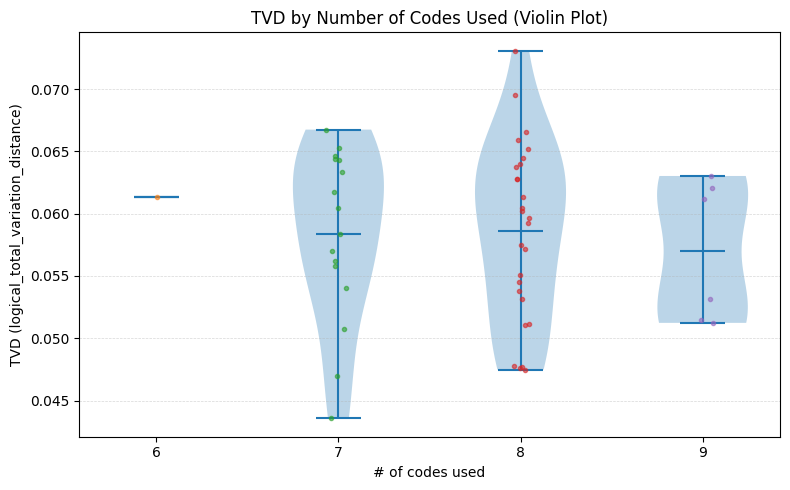

In [ ]:
from pipeline.tasks.scan_random_m import run_random_scan


program_circuit: qiskit.QuantumCircuit = random_clifford_circuit(10, 6)

target_basis = ['x', 'z', 'h', 'rz', 'cx', 'cz', 'measure']

tcirc = qiskit.transpile(
    program_circuit,
    basis_gates=target_basis,
    optimization_level=2,
)
tcirc.measure_all()
# print(tcirc)

# res = pack(tcirc)
# print(res.permutation)

config = PipelineConfig(
    sim_config=ScaledSimulator(alpha=1, repetitions=50_000).with_seed(6),
    verbose=True,
    save=False,
    seed=4,
)

# print(pack(pcirc))

res: RunRecord = run_random_scan(tcirc, 50, config)
df = res.dataframe.df

fig, ax = plot_tvd_violin_by_codes_used(df)
plt.show()

In [ ]:
from pipeline.tasks.scan_random_m import run_random_scan


program_circuit: qiskit.QuantumCircuit = random_clifford_circuit(6, 20)

target_basis = ['x', 'z', 'h', 'rz', 'cx', 'cz', 'measure']

tcirc = qiskit.transpile(
    program_circuit,
    basis_gates=target_basis,
    optimization_level=2,
)
tcirc.measure_all()
# print(tcirc)

# res = pack(tcirc)
# print(res.permutation)

config = PipelineConfig(
    sim_config=ScaledSimulator(alpha=1, repetitions=50_000).with_seed(6),
    verbose=True,
    save=False,
    seed=4,
)

# print(pack(pcirc))

res2: RunRecord = run_random_scan(tcirc, 50, config)



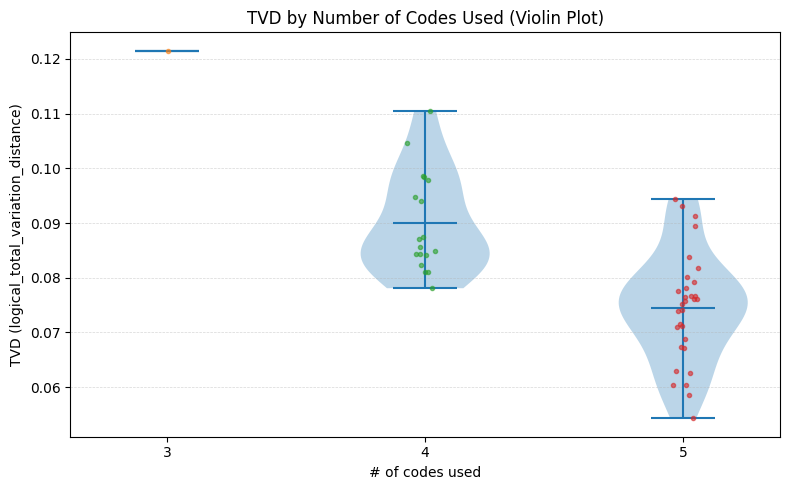

In [6]:
df2 = res2.dataframe.df
fig, ax = plot_tvd_violin_by_codes_used(df2)
plt.show()

         ┌───┐                                              ░ ┌─┐            »
    q_0: ┤ H ├──■───────────────────────────────────────────░─┤M├────────────»
         └───┘┌─┴─┐                                         ░ └╥┘┌─┐         »
    q_1: ─────┤ X ├──■──────────────────────────────────────░──╫─┤M├─────────»
              └───┘┌─┴─┐                                    ░  ║ └╥┘┌─┐      »
    q_2: ──────────┤ X ├──■─────────────────────────────────░──╫──╫─┤M├──────»
                   └───┘┌─┴─┐                               ░  ║  ║ └╥┘┌─┐   »
    q_3: ───────────────┤ X ├──■────────────────────────────░──╫──╫──╫─┤M├───»
                        └───┘┌─┴─┐                          ░  ║  ║  ║ └╥┘┌─┐»
    q_4: ────────────────────┤ X ├──■───────────────────────░──╫──╫──╫──╫─┤M├»
                             └───┘┌─┴─┐                     ░  ║  ║  ║  ║ └╥┘»
    q_5: ─────────────────────────┤ X ├──■──────────────────░──╫──╫──╫──╫──╫─»
                                  └───┘┌─┴─┐        

Simulating circuits: 100%|██████████| 50/50 [10:59<00:00, 13.19s/ sim]


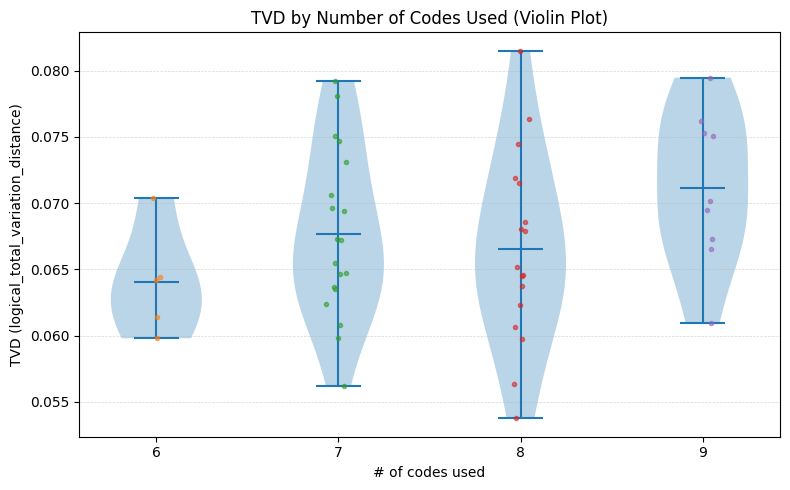

In [10]:
from pipeline.tasks.scan_random_m import run_random_scan
from experiments.shared.example_circuits import n_ghz_state


pcirc = n_ghz_state(10)["program"]
print(pcirc)
config = PipelineConfig(
    sim_config=ScaledSimulator(alpha=1, repetitions=50_000).with_seed(123861827),
    verbose=False,
    save=False,
    seed=41238671,
)

# print(pack(pcirc))

res3: RunRecord = run_random_scan(pcirc, 50, config)
df3 = res3.dataframe.df

fig, ax = plot_tvd_violin_by_codes_used(df3)
plt.show()

        ┌───┐          ┌───┐ ░ ┌─┐      
   q_0: ┤ H ├──■────■──┤ H ├─░─┤M├──────
        └───┘┌─┴─┐  │  └───┘ ░ └╥┘┌─┐   
   q_1: ─────┤ X ├──┼────────░──╫─┤M├───
             └───┘┌─┴─┐      ░  ║ └╥┘┌─┐
   q_2: ──────────┤ X ├──────░──╫──╫─┤M├
                  └───┘      ░  ║  ║ └╥┘
meas: 3/════════════════════════╩══╩══╩═
                                0  1  2 


Simulating circuits: 100%|██████████| 50/50 [03:21<00:00,  4.04s/ sim]


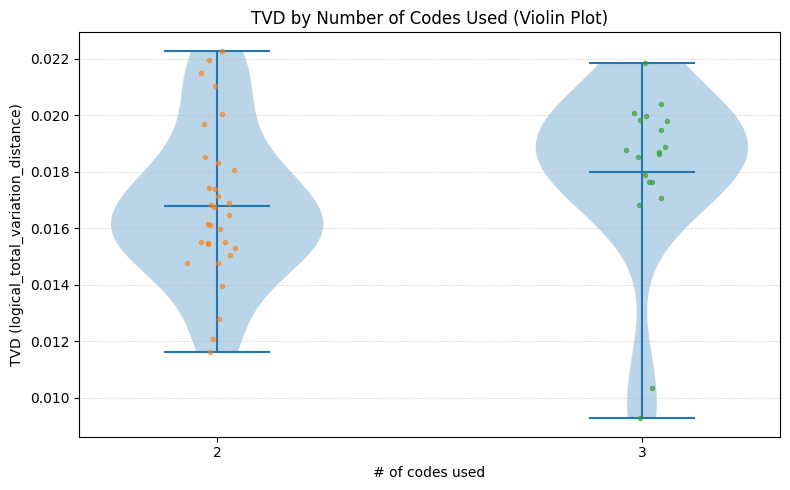

In [3]:
from pipeline.tasks.scan_random_m import run_random_scan
from experiments.shared.example_circuits import unscalable_shors_3


pcirc = unscalable_shors_3()["program"]
print(pcirc)
config = PipelineConfig(
    sim_config=ScaledSimulator(alpha=1, repetitions=50_000).with_seed(123861827),
    verbose=False,
    save=False,
    seed=41238671,
)

# print(pack(pcirc))

res4: RunRecord = run_random_scan(pcirc, 50, config)
df4 = res4.dataframe.df

fig, ax = plot_tvd_violin_by_codes_used(df4)
plt.show()

In [ ]:
from pipeline.tasks.scan_random_m import run_random_scan


program_circuit: qiskit.QuantumCircuit = random_clifford_circuit(4, 40)

target_basis = ['x', 'z', 'h', 'rz', 'cx', 'cz', 'measure']

tcirc = qiskit.transpile(
    program_circuit,
    basis_gates=target_basis,
    optimization_level=2,
)
tcirc.measure_all()
# print(tcirc)

# res = pack(tcirc)
# print(res.permutation)

config = PipelineConfig(
    sim_config=ScaledSimulator(alpha=1, repetitions=10_000).with_seed(6),
    verbose=True,
    save=False,
    seed=4,
)

# print(pack(pcirc))

res5: RunRecord = run_random_scan(tcirc, 76, config)



Simulating circuits:   0%|          | 0/76 [00:00<?, ? sim/s]

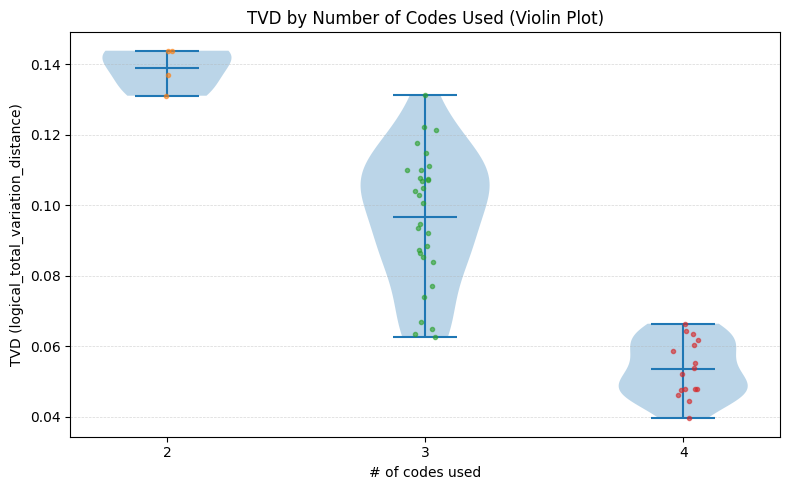

In [4]:
df5 = res5.dataframe.df

fig, ax = plot_tvd_violin_by_codes_used(df5)
plt.show()

Simulating circuits: 100%|██████████| 100/100 [18:41<00:00, 11.22s/ sim]


Run table (n=100)
                         permutation  # codes  fidelity  logical_error_rate  selection rate       TVD  gate count
0   [(2, 0), (1, 1), (3, 1), (0, 0)]        4  0.998778            0.001222         0.03540  0.039013         689
1   [(0, 1), (1, 1), (1, 0), (2, 1)]        3  0.998158            0.001842         0.05148  0.053316         690
2   [(0, 0), (0, 1), (3, 0), (1, 1)]        3  0.999057            0.000943         0.04252  0.034968         702
3   [(3, 1), (2, 0), (0, 0), (3, 0)]        3  0.997396            0.002604         0.03312  0.055235         735
4   [(1, 1), (2, 0), (0, 0), (3, 0)]        4  0.996633            0.003367         0.03184  0.070359         692
5   [(1, 1), (3, 1), (2, 0), (0, 0)]        4  0.998502            0.001498         0.03004  0.043819         715
6   [(0, 1), (2, 0), (1, 0), (3, 0)]        4  0.997314            0.002686         0.03112  0.060595         692
7   [(2, 1), (1, 1), (0, 0), (3, 0)]        4  0.997761            0.0

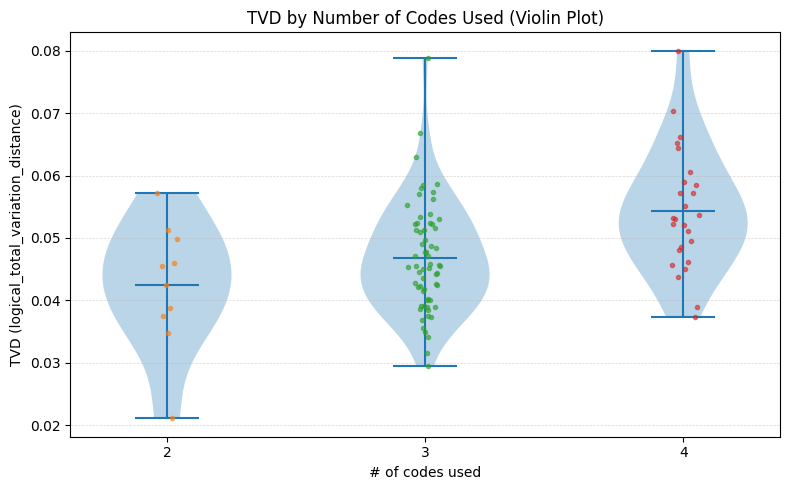

In [6]:
# from permutations.code_sets import generate_uniform_code_sets
# from permutations.generator import random_permutation_from_circuit
from pipeline.tasks.scan_random_m import run_random_scan


# m = 100
# q = program_circuit.num_qubits  # Assumes 1 logical qubit per qubit
# code_sets = generate_uniform_code_sets(q)
# failures = 0
# permutations = []
# while(len(permutations) < m and failures < REPEAT_LIMIT):
#     perm = random_permutation_from_circuit(program_circuit, code_sets)
#     if perm not in permutations:
#         permutations.append(perm)
#     else:
#         failures += 1
# if len(permutations) < m:
#     if failures == REPEAT_LIMIT:
#         warning("Permutation set incomplete, reached 2,500 addition failures to permutation set.")
#     else:
#         warning(f"Permutation set incomplete. For some reason, the permutation set if not of length m but length {len(permutations)}")






program_circuit: qiskit.QuantumCircuit = random_clifford_circuit(4, 50, seed=129379190)

target_basis = ['x', 'z', 'h', 'rz', 'cx', 'cz', 'measure']

tcirc = qiskit.transpile(
    program_circuit,
    basis_gates=target_basis,
    optimization_level=0,
)
tcirc.measure_all()
# print(tcirc)

# res = pack(tcirc)
# print(res.permutation)

config = PipelineConfig(
    sim_config=ScaledSimulator(alpha=1, repetitions=25_000).with_seed(6),
    verbose=True,
    save=False,
    seed=4,
)

# print(pack(pcirc))

res5: RunRecord = run_random_scan(tcirc, 100, config)
df5 = res5.dataframe.df
fig, ax = plot_tvd_violin_by_codes_used(df5)
plt.show()

Simulating circuits: 100%|██████████| 50/50 [09:15<00:00, 11.11s/ sim]


Run table (n=50)
                         permutation  # codes  fidelity  logical_error_rate  selection rate       TVD  gate count
0   [(0, 0), (2, 1), (1, 0), (1, 1)]        3  0.998747            0.001253         0.04696  0.042535         694
1   [(2, 0), (2, 1), (0, 0), (0, 1)]        2  0.999069            0.000931         0.07092  0.036791         696
2   [(1, 1), (0, 0), (1, 0), (0, 1)]        2  0.998718            0.001282         0.09012  0.045812         674
3   [(1, 1), (2, 1), (0, 0), (0, 1)]        3  0.998005            0.001995         0.04676  0.046695         697
4   [(1, 0), (1, 1), (3, 1), (2, 0)]        3  0.995411            0.004589         0.04028  0.078596         724
5   [(2, 0), (1, 0), (2, 1), (0, 1)]        3  0.998174            0.001826         0.05052  0.047801         699
6   [(0, 0), (0, 1), (3, 1), (1, 0)]        3  0.997494            0.002506         0.03824  0.063294         724
7   [(2, 1), (3, 1), (1, 1), (1, 0)]        3  0.996762            0.00

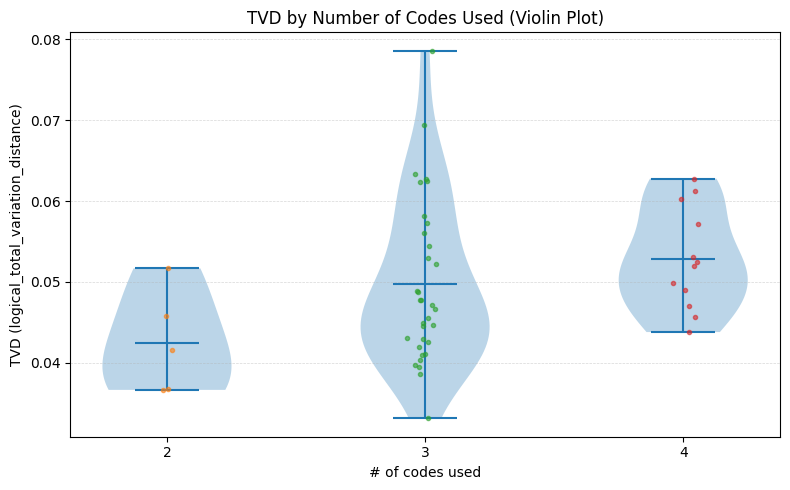

In [ ]:
program_circuit: qiskit.QuantumCircuit = random_clifford_circuit(4, 50, seed=129379190)

target_basis = ['x', 'z', 'h', 'rz', 'cx', 'cz', 'measure']

tcirc = qiskit.transpile(
    program_circuit,
    basis_gates=target_basis,
    optimization_level=0,
)
tcirc.measure_all()
# print(tcirc)

# res = pack(tcirc)
# print(res.permutation)

config = PipelineConfig(
    sim_config=ScaledSimulator(alpha=1, repetitions=25_000).with_seed(6),
    verbose=True,
    save=False,
    seed=4,
)

# print(pack(pcirc))

res5: RunRecord = run_random_scan(tcirc, 50, config)
df5 = res5.dataframe.df
fig, ax = plot_tvd_violin_by_codes_used(df5)
plt.show()

In [12]:
from pipeline.tasks.scan_random_m import run_random_scan

program_circuit: qiskit.QuantumCircuit = random_clifford_circuit(4, 50, seed=129379190)
print(program_circuit)
print()

target_basis = ['x', 'z', 'h', 'rz', 'cx', 'cz', 'measure']

tcirc = qiskit.transpile(
    program_circuit,
    basis_gates=target_basis,
    optimization_level=0,
)
tcirc.measure_all()
# print(tcirc)

# res = pack(tcirc)
# print(res.permutation)

config = PipelineConfig(
    sim_config=ScaledSimulator(alpha=1, repetitions=1).with_seed(6),
    verbose=True,
    save=False,
    seed=4,
)

# print(pack(pcirc))

# res5: RunRecord = 
run_random_scan(tcirc, 2000, config)
# df5 = res5.dataframe.df
# fig, ax = plot_tvd_violin_by_codes_used(df5)
# plt.show()

     ┌───┐┌───┐      ┌────────┐        ┌──────┐ ┌───┐  ┌───┐                »
q_0: ┤ Z ├┤ X ├──────┤0       ├────────┤1     ├─┤ Z ├──┤ Y ├───────────■────»
     ├───┤├───┤┌────┐│        │┌──────┐│      │┌┴───┴─┐├───┤┌───┐      │    »
q_1: ┤ Y ├┤ Y ├┤ √X ├┤  Iswap ├┤ √Xdg ├┤  Dcx ├┤0     ├┤ X ├┤ Z ├──■───■──■─»
     └─┬─┘├───┤└────┘│        │└──────┘│      ││      │├───┤└───┘  │      │ »
q_2: ──┼──┤ S ├──────┤1       ├────────┤0     ├┤  Ecr ├┤ H ├───────┼──────┼─»
       │  ├───┤      └────────┘        └──────┘│      │├───┤     ┌─┴─┐    │ »
q_3: ──■──┤ I ├────────────────────────────────┤1     ├┤ S ├─────┤ X ├────■─»
          └───┘                                └──────┘└───┘     └───┘      »
«     ┌───┐ ┌───┐     ┌──────┐                                ┌───┐           »
«q_0: ┤ Y ├─┤ Y ├───■─┤ √Xdg ├─────────────────────────────X──┤ Y ├──■────■───»
«     └─┬─┘ └─┬─┘   │ ├──────┤┌────┐┌───┐   ┌──────┐┌───┐  │  └───┘  │    │   »
«q_1: ──■─────■─────┼─┤0     ├┤ √X ├┤ S ├─X─┤0     ├┤ X ├─

In [ ]:
from pipeline.tasks.scan_random_m import run_random_scan

program_circuit: qiskit.QuantumCircuit = random_clifford_circuit(10, 100, seed=129379190,
    gates=['x', 'z', 's', 'h', 'cx', 'cz'],
)
program_circuit.measure_all()
# print(tcirc)

# res = pack(tcirc)
# print(res.permutation)

config = PipelineConfig(
    sim_config=ScaledSimulator(alpha=1, repetitions=25_000).with_seed(6).with_stim().with_distance_based_noise(),
    verbose=True,
    save=False,
    seed=4,
)

packer = HeuristicPacker()
packing = packer.pack(program_circuit, max_patches=6)
perm = packer.packing_to_permutation(packing.qubit_to_patch)

resStim: RunRecord = run_random_scan(program_circuit, 20, config, added_perms=[perm])
dfStim = resStim.dataframe.df
fig, ax = plot_tvd_violin_by_codes_used(dfStim)
plt.show()

ValueError: Circuit with 10 qubits cannot fit in 3 patches of capacity 2.